In [ ]:
import qiskit.qasm2

NameError: name 'filename' is not defined

In [2]:
import qiskit.qasm2

program = """
    OPENQASM 2.0;
    include "qelib1.inc";
    qreg q[2];
    creg c[2];

    h q[0];
    cx q[0], q[1];

    measure q -> c;
"""
circuit = qiskit.qasm2.loads(program)
circuit.draw()

┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1

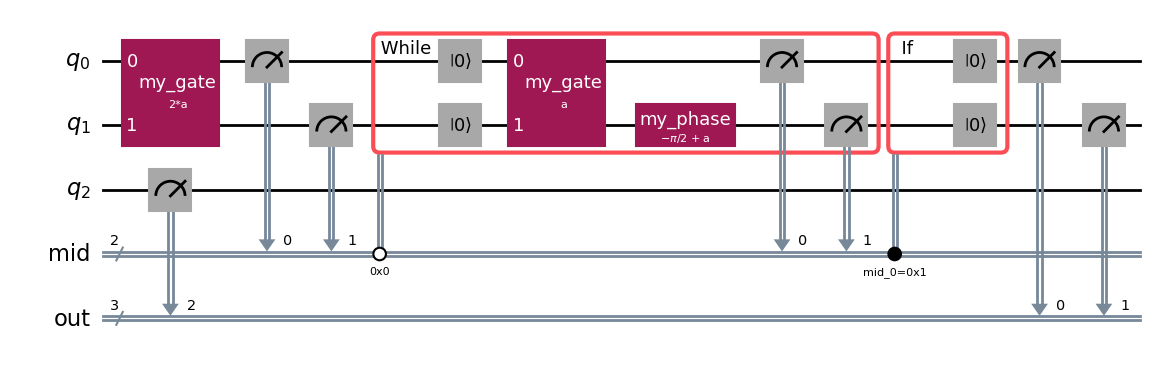

In [3]:
import qiskit.qasm3

program = """
    OPENQASM 3.0;
    include "stdgates.inc";

    input float[64] a;
    qubit[3] q;
    bit[2] mid;
    bit[3] out;

    let aliased = q[0:1];

    gate my_gate(a) c, t {
      gphase(a / 2);
      ry(a) c;
      cx c, t;
    }
    gate my_phase(a) c {
      ctrl @ inv @ gphase(a) c;
    }

    my_gate(a * 2) aliased[0], q[{1, 2}][0];
    measure q[0] -> mid[0];
    measure q[1] -> mid[1];

    while (mid == "00") {
      reset q[0];
      reset q[1];
      my_gate(a) q[0], q[1];
      my_phase(a - pi/2) q[1];
      mid[0] = measure q[0];
      mid[1] = measure q[1];
    }

    if (mid[0]) {
      let inner_alias = q[{0, 1}];
      reset inner_alias;
    }

    out = measure q;
"""
circuit = qiskit.qasm3.loads(program)
circuit.draw("mpl")

In [4]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

# Create original circuit
qc = QuantumCircuit(2)

qc.h(0)
qc.cx(0, 1)
qc.t(1)

print("Original circuit:")
print(qc.draw())

# Create simulator
backend = AerSimulator()

# Transpile circuit for the simulator
transpiled_qc = transpile(
    qc,
    backend=backend,
    optimization_level=1
)

print("Transpiled circuit:")
print(transpiled_qc.draw())

print("Original depth:", qc.depth())
print("Transpiled depth:", transpiled_qc.depth())
print("Original gates:", qc.count_ops())
print("Transpiled gates:", transpiled_qc.count_ops())

Original circuit:
     ┌───┐          
q_0: ┤ H ├──■───────
     └───┘┌─┴─┐┌───┐
q_1: ─────┤ X ├┤ T ├
          └───┘└───┘
Transpiled circuit:
     ┌───┐          
q_0: ┤ H ├──■───────
     └───┘┌─┴─┐┌───┐
q_1: ─────┤ X ├┤ T ├
          └───┘└───┘
Original depth: 3
Transpiled depth: 3
Original gates: OrderedDict([('h', 1), ('cx', 1), ('t', 1)])
Transpiled gates: OrderedDict([('h', 1), ('cx', 1), ('t', 1)])
